# ISDA CDM Schema Graph

The FINOS [Common Domain Model](https://cdm.finos.org/) (ISDA CDM) standardises how financial products are traded and managed across the transaction lifecycle. This notebook turns the CDM type system into a GestaltDB property graph: one node per CDM type, edges for properties (`HAS_PROPERTY`), inheritance (`EXTENDS`), and namespace membership (`IN_NAMESPACE` / `CHILD_NAMESPACE`).

**Source:** the [`finos-cdm`](https://github.com/finos/common-domain-model/tree/master/python) PyPI distribution, which ships every CDM type as a Pydantic v2 class generated from the authoritative Rune model. No web scraping is needed; the companion JSON-schema parser in `cdm_schema_graph/parser.py` remains as an offline/network fallback (see appendix).

The database cells use the optional **LevelDB backend**. Install extras in your Jupyter kernel (`pip install gestaltdb[leveldb] finos-cdm`), or run `uv sync --extra leveldb` in the checkout and `uv pip install finos-cdm`. Run cells top to bottom, then run the cleanup cell.

## Imports and Checkout Setup

Supports launching Jupyter from the repository root or `notebooks/`. The sidecar package `cdm_schema_graph/` lives next to this notebook and is *example code, not core library code*.

In [12]:
# !pip install finos-cdm
from pathlib import Path
import os
curr_path = Path('.')
if 'notebooks' in curr_path.absolute()._str:

    os.chdir('..')
    import sys
    sys.path.append(curr_path.absolute())


In [14]:
import importlib.util
import sys
import time
from pathlib import Path
from tempfile import TemporaryDirectory

for candidate in (Path.cwd(), Path.cwd().parent):
    if (candidate / 'src' / 'gestaltdb').is_dir():
        sys.path.insert(0, str(candidate / 'src'))
    if (candidate / 'notebooks' / 'cdm_schema_graph').is_dir():
        sys.path.insert(0, str(candidate / 'notebooks'))

if importlib.util.find_spec('finos.cdm') is None:
    raise RuntimeError("Install the CDM models first: pip install 'finos-cdm'")

from IPython.display import SVG, display
from gestaltdb.graphdb import GraphDB
from gestaltdb.viz.api import VizOptions

from cdm_schema_graph import PARSER_VERSION, build_graph_payload, load_into_graph
from cdm_schema_graph import cdm_package_version, load_cdm_result
from cdm_schema_graph import queries as Q

print('parser version:', PARSER_VERSION)
print('finos-cdm version:', cdm_package_version())

parser version: 0.2.0
finos-cdm version: 7.8.0


## Load CDM Types from Pydantic Models

`load_cdm_result()` imports every `finos.cdm` type module (bundle-first, so circular imports resolve), reads field descriptions/cardinality from Pydantic `model_fields`, class and enum-member docs from generated sources, detects choice types via `condition_N_Choice` validators, and records inheritance as `base_types`. Set `LIMIT` for a fast smoke run; the default loads the full model (~1k types, a few seconds).

In [19]:
%%capture
LIMIT = None  # e.g. 60 for a smoke run

started = time.time()
result, skipped = load_cdm_result(limit=LIMIT)
print(f'loaded {result.files_parsed} types in {time.time() - started:.1f}s')
print('source:', result.source, '| cdm:', result.cdm_version, '| parser:', result.parser_version)
print('dangling refs:', result.dangling_refs)
print('collisions:', result.collisions)
print('skipped non-model modules:', len(skipped))

## Spot-Check Key Types

`Trade` keeps its description, required fields, and array cardinality; `Asset` is recognised as a *choice* type; `LegalAgreement` records its base type; enums keep per-value documentation.

In [20]:
trade = result.records['Trade']
print('Trade:', trade.kind, '| bases:', trade.base_types)
print('desc:', trade.description[:110])
for prop in trade.properties[:5]:
    print(f'  {prop.name}: -> {prop.ref_target} array={prop.is_array} required={prop.required}')

asset = result.records['Asset']
print('\nAsset:', asset.kind, '|', (asset.description or '')[:90])
print('options:', [(p.name, p.ref_target) for p in asset.properties])

agreement = result.records['LegalAgreement']
print('LegalAgreement bases:', agreement.base_types)

bdc = result.records['BusinessDayConventionEnum']
print('\nEnum values:', bdc.enum_values[:4])
print('FOLLOWING:', bdc.enum_details[0]['description'][:90])

Trade: object | bases: ['TradableProduct']
desc: Defines the output of a financial transaction between parties - a Business Event. A Trade impacts the financia
  product: -> NonTransferableProduct array=False required=True
  tradeLot: -> TradeLot array=True required=True
  counterparty: -> Counterparty array=True required=True
  ancillaryParty: -> None array=False required=False
  adjustment: -> NotionalAdjustmentEnum array=False required=False

Asset: choice | An Asset is defined as something that can be owned and transferred in the financial market
options: [('Cash', 'Cash'), ('Commodity', 'Commodity'), ('DigitalAsset', 'DigitalAsset'), ('Instrument', 'Instrument')]
LegalAgreement bases: ['LegalAgreementBase']

Enum values: ['FOLLOWING', 'FRN', 'MODFOLLOWING', 'MODPRECEDING']
FOLLOWING: The non-business date will be adjusted to the first following day that is a business day


## Corpus Distributions

In [21]:
from collections import Counter

print('by kind:', dict(Counter(r.kind for r in result.records.values())))
for namespace, count in Counter(r.coarse_namespace for r in result.records.values()).most_common():
    print(f'  {namespace:28s} {count}')

by kind: {'object': 762, 'enum': 280, 'choice': 19}
  cdm-legaldocumentation       322
  cdm-product                  274
  cdm-event                    148
  cdm-base-staticdata          119
  cdm-observable               119
  cdm-base-datetime            44
  cdm-base-math                30
  cdm-margin                   5


## Build the GestaltDB Graph

Types become `CdmType` nodes; properties, inheritance, and namespace membership become typed edges. Every node/edge carries `parser_version`, and a `cdm:dataset:*` node records provenance. Rerunning the cell closes the previous graph first.

In [22]:
previous_graph = globals().pop('graph', None)
if previous_graph is not None:
    previous_graph.close()
previous_workspace = globals().pop('workspace', None)
if previous_workspace is not None:
    previous_workspace.cleanup()

workspace = TemporaryDirectory(prefix='gestaltdb_cdm_')
workdir = Path(workspace.name)
artifacts_dir = workdir / 'artifacts'
artifacts_dir.mkdir()
graph = GraphDB.create(str(workdir / 'graph'), backend="leveldb", serializer="json")

payload = build_graph_payload(result, package_version=result.cdm_version)
stats = load_into_graph(graph, payload)
print(stats)
print('Artifacts:', artifacts_dir)

{'parser_version': '0.2.0', 'cdm_version': '7.8.0', 'source': 'pydantic', 'type_nodes': 1061, 'namespace_nodes': 45, 'node_count': 1105, 'edge_count': 3308, 'has_property_edges': 2078, 'extends_edges': 125, 'skipped_primitive_or_dangling': 1316, 'dangling_refs': 0}
Artifacts: /tmp/gestaltdb_cdm_aptv51i5/artifacts


## Explore with Cypher

Hub types with the most incoming property references, the `Trade` neighbourhood, the `Asset` choice hierarchy, `LegalAgreement`, and the inheritance chain.

In [23]:
print('=== top hubs ===')
for row in graph.query(Q.TYPE_HUBS).records[:10]:
    print(f"  {row['type']:40s} {row['in_degree']}")

print('\n=== Trade neighbourhood ===')
for row in graph.query(Q.TRADE_NEIGHBOURHOOD).records:
    print(f"  {row['property']:20s} -> {row['target']}")

print('\n=== Asset choice hierarchy ===')
for row in graph.query(Q.ASSET_HIERARCHY).records:
    print(f"  Asset -> {row['child']} -> {row['grandchild']}")

print('\n=== Trade inheritance ===')
for row in graph.query(Q.TRADE_INHERITANCE_CHAIN).records:
    print(f"  Trade extends {row['ancestor']}")

=== top hubs ===
  CounterpartyRoleEnum                     64
  Money                                    57
  Party                                    44
  LegalEntity                              27
  Price                                    26
  AdjustableOrRelativeDate                 20
  BusinessCenterTime                       17
  AssetIdentifier                          17
  AssetTypeEnum                            17
  BusinessCenters                          17

=== Trade neighbourhood ===
  adjustment           -> NotionalAdjustmentEnum
  collateral           -> Collateral
  contractDetails      -> ContractDetails
  counterparty         -> Counterparty
  executionDetails     -> ExecutionDetails
  product              -> NonTransferableProduct
  tradeIdentifier      -> TradeIdentifier
  tradeLot             -> TradeLot
  tradeTime            -> TimeZone

=== Asset choice hierarchy ===
  Asset -> Cash -> AssetIdentifier
  Asset -> Cash -> AssetPartyRole
  Asset -> Cash -> Ass

## Visualize: Trade Neighbourhood

Edges are labelled with CDM property names; node colours distinguish objects, choices, and enums.

In [24]:
trade_options = VizOptions(
    title='CDM Trade neighbourhood (finos-cdm)',
    height=650, theme='light', charge=-220, link_distance=120,
    node_label_property='name', node_color_property='kind',
    edge_labels='all', edge_label_property='property_name', label_max_length=28,
)
trade_figure = graph.visualize(Q.TRADE_GRAPH, options=trade_options)
assert len(trade_figure.viz.nodes) > 0, 'viz query returned no graph entities'
trade_figure.save(artifacts_dir / 'cdm-trade.html')
print(repr(trade_figure))
trade_figure

VizFigure(nodes=10, edges=9)


VizFigure(nodes=10, edges=9)

## Visualize: Asset Choice Hierarchy and LegalAgreement

`Asset` fans out to its `Cash` / `Commodity` / `DigitalAsset` / `Instrument` options, each expanding one more hop; `LegalAgreement` shows its self-referential `relatedAgreements` and umbrella terms.

In [25]:
from dataclasses import replace

asset_figure = graph.visualize(Q.ASSET_GRAPH,
    options=replace(trade_options, title='CDM Asset choice hierarchy'))
assert len(asset_figure.viz.nodes) > 0, 'viz query returned no graph entities'
asset_figure.save(artifacts_dir / 'cdm-asset.html')
print(repr(asset_figure))
asset_figure

VizFigure(nodes=14, edges=19)


VizFigure(nodes=14, edges=19)

In [26]:
from dataclasses import replace

legal_figure = graph.visualize(Q.LEGAL_AGREEMENT_GRAPH,
    options=replace(trade_options, title='CDM LegalAgreement neighbourhood'))
assert len(legal_figure.viz.nodes) > 0, 'viz query returned no graph entities'
legal_figure.save(artifacts_dir / 'cdm-legal-agreement.html')
print(repr(legal_figure))
legal_figure

VizFigure(nodes=5, edges=4)


VizFigure(nodes=5, edges=4)

## Visualize: Metadata Backbone

Namespace nodes (`ns:cdm-event`, `ns:cdm-legaldocumentation`, …) connect fine-grained type namespaces to coarse domains and the `ns:cdm` root. This view uses a static SVG as well, so it renders without a browser.

In [27]:
from dataclasses import replace

meta_figure = graph.visualize(Q.NAMESPACE_GRAPH,
    options=replace(trade_options, title='CDM namespace backbone',
                    node_color_property='name', edge_labels='off'))
assert len(meta_figure.viz.nodes) > 0, 'viz query returned no graph entities'
meta_figure.save(artifacts_dir / 'cdm-namespaces.html')
print(repr(meta_figure))
meta_figure

VizFigure(nodes=43, edges=44)


VizFigure(nodes=43, edges=44)

In [28]:
whole = graph.visualize(
    "MATCH (n) OPTIONAL MATCH (n)-[r]->(m) RETURN n, r, m",
    options=VizOptions(
        title="CDM full schema graph",
        height=800,
        node_label_property="name",
        node_color_property="kind",
        edge_labels="off",  # 3k edge labels is unreadable; hover still works
    ),
)
whole.save(artifacts_dir / "cdm-whole.html")
whole

VizFigure(nodes=1105, edges=3308)

Trade SVG: /tmp/gestaltdb_cdm_aptv51i5/artifacts/cdm-trade.svg


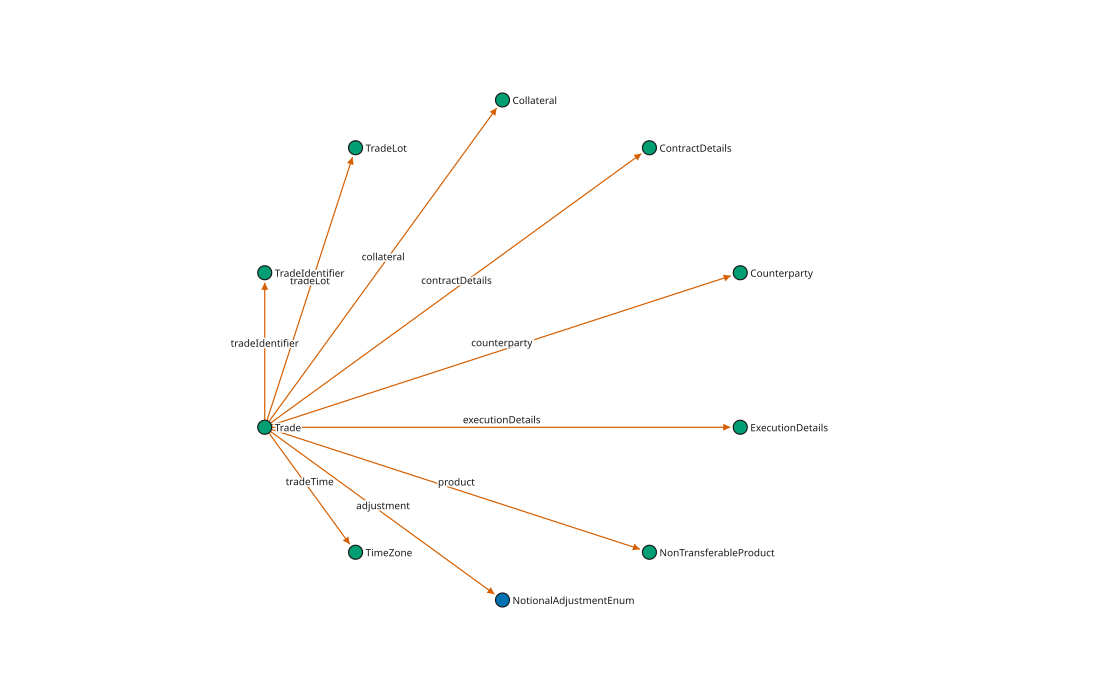

In [31]:
svg_path = trade_figure.save_svg(artifacts_dir / 'cdm-trade.svg', width=1100, height=700, layout='circle')
print('Trade SVG:', svg_path)
display(SVG(data=trade_figure.as_svg(width=1100, height=700, layout='circle')))

## Provenance: Parser Version on Every Entity

The dataset node records which parser build produced the graph; spot-checks confirm the stamp on sampled type nodes and property edges.

In [32]:
dataset = graph.query('MATCH (d:CdmDataset) RETURN d.name AS name, d.source AS source, d.cdm_version AS cdm, d.parser_version AS parser').records
print(dataset)
assert dataset[0]['parser'] == PARSER_VERSION and dataset[0]['source'] == 'pydantic'

stamped = graph.query(
    'MATCH (t:CdmType {name: "Trade"})-[r:HAS_PROPERTY]->(d) '
    'RETURN r.parser_version AS parser LIMIT 1'
).records
assert stamped[0]['parser'] == PARSER_VERSION
print('parser_version stamp OK:', PARSER_VERSION)

[{'name': 'CDM 7.8.0', 'source': 'pydantic', 'cdm': '7.8.0', 'parser': '0.2.0'}]
parser_version stamp OK: 0.2.0


## Appendix: JSON-Schema Fallback (Optional, Needs Network)

If `finos-cdm` cannot be installed, `CdmSchemaParser` downloads the same model from `https://cdm.finos.org/schemas/7.0/` and produces identical node/edge payloads (minus `EXTENDS` inheritance). Set `RUN_JSON_FALLBACK = True` to try it with a small file limit.

In [33]:
RUN_JSON_FALLBACK = False
if RUN_JSON_FALLBACK:
    from cdm_schema_graph import CdmSchemaParser

    fallback = CdmSchemaParser(cache_dir=str(workdir / 'cdm-json'))
    names = fallback.list_remote_schema_files()
    print('remote schemas:', len(names))
    schemas = fallback.download_all(names=names, limit=20)
    json_result = fallback.parse_all(schemas=schemas)
    print(fallback.summary(json_result))
    json_payload = build_graph_payload(json_result, source_url=fallback.base_url)
    print(json_payload.stats)
else:
    print('JSON fallback skipped (set RUN_JSON_FALLBACK = True to run)')


JSON fallback skipped (set RUN_JSON_FALLBACK = True to run)


## Close the Store and Remove Temporary Artifacts

Copy any HTML/SVG files you want to retain before running this cell; it removes the disposable workspace. Displayed figures already contain their graph payloads and remain usable after the database closes.

In [34]:
graph.close()
workspace.cleanup()
del graph, workspace
print('Closed the store and removed the temporary workspace.')

Closed the store and removed the temporary workspace.
